# LAB 12 — Artificial Neural Networks: The Perceptron
## Student Information
- **Name:** Sneha Kanjwani
- **Roll No:** 023-24-0273
- **Section:** H
- **Date:** 17-11-2026

**Dataset:** Iris (sklearn built-in) · Use `random_state=42` everywhere · Write a 1–2 sentence interpretation under every plot and table.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris, make_classification
from sklearn.linear_model import Perceptron, LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report

np.random.seed(42)
iris = load_iris()
print("Iris loaded:", iris.data.shape, "| Classes:", iris.target_names)

Iris loaded: (150, 4) | Classes: ['setosa' 'versicolor' 'virginica']


## Part 1 — The Neuron From Scratch

### Task 1.1 — Weighted sum, step function and predict
Write `weighted_sum`, `step_function`, `predict`. Verify slide 16 (`predict([0.6,0.8],[2,3],-2)` → 1) and slide 17 (w=[1,−0.5], b=0.5; inputs [1,1],[2,1],[0,3] → 1, 1, 0).

In [3]:
# Task 1.1
def weighted_sum(w, x, b):
    return np.dot(w, x) + b

def step_function(z):
    return 1 if z >=0 else 0

def predict(w, x, b):
    z = weighted_sum(w, x, b)
    return step_function(z)

result = predict([0.6, 0.8], [2, 3], -2)
print("Slide 16 prediction:", result)

w = [1, -0.5]
b = 0.5

inputs = [[1, 1], [2, 1], [0, 3]]

for x in inputs:
    print("Input:", x, "| Prediction:", predict(w, x, b))

Slide 16 prediction: 1
Input: [1, 1] | Prediction: 1
Input: [2, 1] | Prediction: 1
Input: [0, 3] | Prediction: 0


### Task 1.2 — One full epoch on the AND gate, by hand
AND: (0,0,0), (0,1,0), (1,0,0), (1,1,1). Start w=[0.2, −0.1], b=0, η=0.1. Print z, ŷ, e and the new w, b for each row; then the mistake count and "Converged!" / "Keep training.".

In [4]:
# Task 1.2
X_and = [[0, 0], [0, 1], [1, 0], [1, 1]]
y_and = [0, 0, 0, 1]

w = np.array([0.2, -0.1], dtype=float)
b = 0.0
eta = 0.1

mistakes = 0

for x, y in zip(X_and, y_and):
    x = np.array(x)
    z = weighted_sum(w, x, b)
    y_hat = step_function(z)

    e = y - y_hat
    if e != 0:
        mistakes += 1
        w = w + eta * e * x
        b = b + eta * e

    print(f"Input: {x}, Actual: {y}, z: {z:.2f}, "
          f"Prediction: {y_hat}, Error: {e}")
    print(f"Updated weights: {w}, Updated bias: {b:.2f}")

print("Final weights:", w)
print("Final bias:", b)
print("Total mistakes:", mistakes)

if mistakes == 0:
    print("Converged!")
else:
    print("Keep training.")

Input: [0 0], Actual: 0, z: 0.00, Prediction: 1, Error: -1
Updated weights: [ 0.2 -0.1], Updated bias: -0.10
Input: [0 1], Actual: 0, z: -0.20, Prediction: 0, Error: 0
Updated weights: [ 0.2 -0.1], Updated bias: -0.10
Input: [1 0], Actual: 0, z: 0.10, Prediction: 1, Error: -1
Updated weights: [ 0.1 -0.1], Updated bias: -0.20
Input: [1 1], Actual: 1, z: -0.20, Prediction: 0, Error: 1
Updated weights: [0.2 0. ], Updated bias: -0.10
Final weights: [0.2 0. ]
Final bias: -0.1
Total mistakes: 3
Keep training.


# Interpretation:

During this epoch, the perceptron made 3 mistakes out of 4 predictions. It updated its weights and bias whenever it predicted incorrectly, but it has not yet learned the AND gate correctly. Therefore, it needs more training.

## Part 2 — Train a Perceptron From Scratch

### Task 2.1 — Implement `train_perceptron`
`train_perceptron(X, y, eta=0.1, max_epochs=100)`: start from zeros, update on every mistake, record mistakes per epoch, stop after a zero-mistake epoch. Train on OR (y = [0,1,1,1]) and print w, b.

In [5]:
# Task 2.1
def train_perceptron(X, y, eta=0.1, max_epochs=100):
    w = np.zeros(X.shape[1])
    b = 0.0
    mistakes = []

    for epoch in range(max_epochs):
        errors = 0

        for x, target in zip(X, y):
            z = weighted_sum(w, x, b)
            y_hat = step_function(z)

            e = target - y_hat

            if e != 0:
                w = w + eta * e * x
                b = b + eta * e
                errors += 1

        mistakes.append(errors)

        if errors == 0:
            break

    return w, b, mistakes


X_or = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
y_or = np.array([0, 1, 1, 1])

w_or, b_or, mistakes_or = train_perceptron(X_or, y_or)

print("Final weights:", w_or)
print("Final bias:", b_or)
print("Mistakes per epoch:", mistakes_or)
print("Total epochs:", len(mistakes_or))

Final weights: [0.1 0.1]
Final bias: -0.1
Mistakes per epoch: [2, 2, 1, 0]
Total epochs: 4


### Task 2.2 — Plot mistakes per epoch
Title "Perceptron training on OR gate", axes "Epoch" / "Mistakes"; mark the final epoch with a red dot.

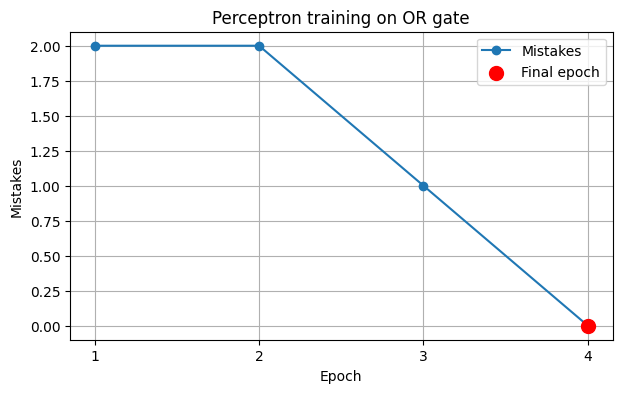

In [6]:
# Task 2.2
epochs = range(1, len(mistakes_or) + 1)

plt.figure(figsize=(7, 4))

plt.plot(epochs, mistakes_or, marker='o', label='Mistakes')
plt.scatter(epochs[-1], mistakes_or[-1], color='red',
            s=100, label='Final epoch', zorder=5)

plt.title("Perceptron training on OR gate")
plt.xlabel("Epoch")
plt.ylabel("Mistakes")
plt.xticks(list(epochs))
plt.legend()
plt.grid(True)
plt.show()

**Interpretation:** The perceptron made 2 mistakes in epochs 1 and 2, 1 mistake in epoch 3 and 0 mistakes in epoch 4 (mistakes = [2, 2, 1, 0]). The count falls to zero, so it learned OR and stopped after 4 epochs, as expected for linearly separable data.

## Part 3 — The Decision Boundary

### Task 3.1 — Plot the OR gate with its boundary
Boundary: x₂ = −(w₁/w₂)x₁ − b/w₂ over `np.linspace(-0.5, 1.5, 100)`. Class 0 blue circles, class 1 red squares, boundary black dashed. Write a reusable `plot_boundary(ax, w, b)` that handles w₂ = 0.

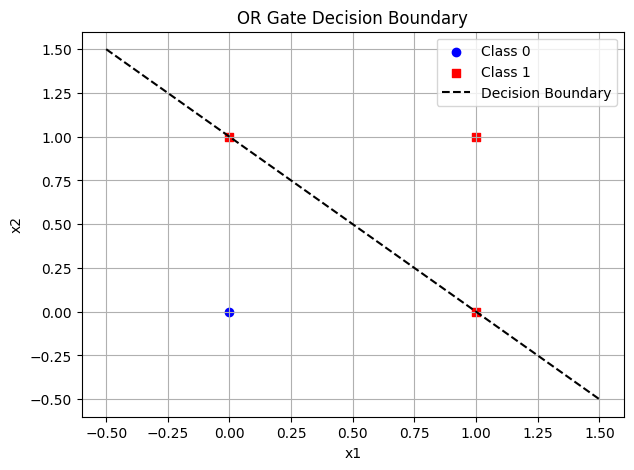

In [7]:
# Task 3.1
def plot_boundary(ax, w, b, x_range=(-0.5, 1.5)):
    x1 = np.linspace(x_range[0], x_range[1], 100)
    if w[1] != 0:
        x2 = -(w[0] / w[1]) * x1 - b / w[1]
        ax.plot(x1, x2, 'k--', label='Decision Boundary')
    elif w[0] != 0:
        ax.axvline(x=-b / w[0], color='black', linestyle='--', label='Decision Boundary')


fig, ax = plt.subplots(figsize=(7, 5))

class_0 = X_or[y_or == 0]
class_1 = X_or[y_or == 1]

ax.scatter(class_0[:, 0], class_0[:, 1],
           color='blue', marker='o', label='Class 0')

ax.scatter(class_1[:, 0], class_1[:, 1],
           color='red', marker='s', label='Class 1')

plot_boundary(ax, w_or, b_or)

ax.set_title("OR Gate Decision Boundary")
ax.set_xlabel("x1")
ax.set_ylabel("x2")
ax.legend()
ax.grid(True)

plt.show()

**Interpretation:** The decision boundary is a straight line that separates the class 0 point (0,0) from the class 1 points. The region where w1x1 + w2x2 + b >= 0 represents the side predicted as class 1, while the other side represents class 0. ŷ = 1 on the upper-right side of the line, where w·x + b ≥ 0.

### Task 3.2 — With and without bias
Train both versions on X=[[1,0],[0,1],[2,1],[1,2]], y=[0,0,1,1]; plot the two boundaries side by side. Did the no-bias version converge?

WITH BIAS
Weights: [0.1 0.1]
Bias: -0.2
Epochs: 4
Final mistakes: 0

WITHOUT BIAS
Weights: [0.1 0. ]
Bias: 0.0
Epochs: 100
Final mistakes: 2


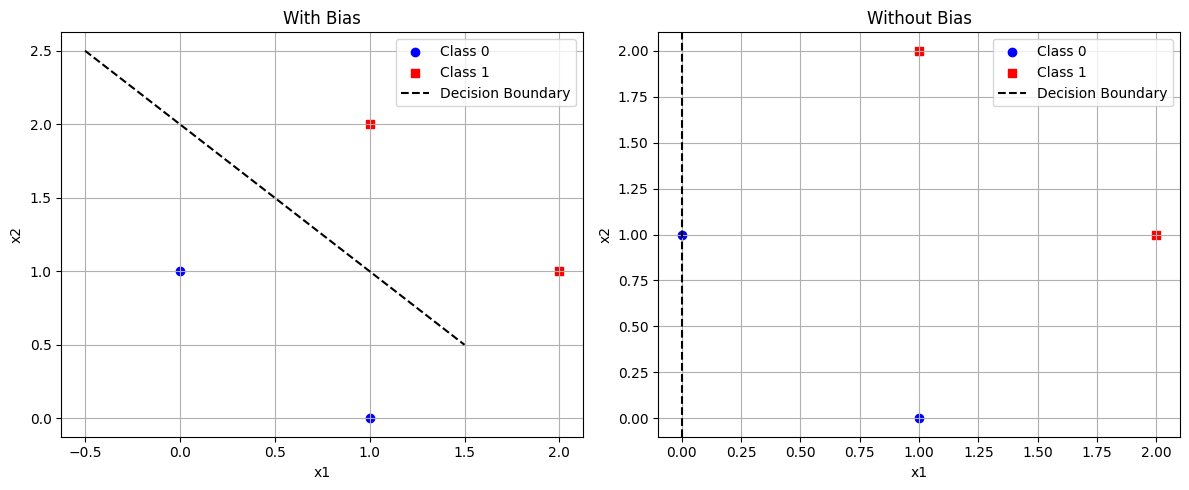

No-bias version did not converge.


In [8]:
# Task 3.2
X_bias = np.array([[1, 0], [0, 1], [2, 1], [1, 2]])
y_bias = np.array([0, 0, 1, 1])

w_with, b_with, mistakes_with = train_perceptron(
    X_bias, y_bias, eta=0.1, max_epochs=100
)

def train_perceptron_no_bias(X, y, eta=0.1, max_epochs=100):
    w = np.zeros(X.shape[1])
    b = 0.0
    mistakes = []

    for epoch in range(max_epochs):
        errors = 0

        for x, target in zip(X, y):
            z = np.dot(w, x)  
            y_hat = step_function(z)

            e = target - y_hat

            if e != 0:
                w = w + eta * e * x
                errors += 1

        mistakes.append(errors)

        if errors == 0:
            break

    return w, b, mistakes


w_without, b_without, mistakes_without = train_perceptron_no_bias(
    X_bias, y_bias, eta=0.1, max_epochs=100
)

print("WITH BIAS")
print("Weights:", w_with)
print("Bias:", b_with)
print("Epochs:", len(mistakes_with))
print("Final mistakes:", mistakes_with[-1])

print("\nWITHOUT BIAS")
print("Weights:", w_without)
print("Bias:", b_without)
print("Epochs:", len(mistakes_without))
print("Final mistakes:", mistakes_without[-1])

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, w, b, title in [
    (axes[0], w_with, b_with, "With Bias"),
    (axes[1], w_without, b_without, "Without Bias")
]:
    class_0 = X_bias[y_bias == 0]
    class_1 = X_bias[y_bias == 1]

    ax.scatter(class_0[:, 0], class_0[:, 1],
               color='blue', marker='o', label='Class 0')

    ax.scatter(class_1[:, 0], class_1[:, 1],
               color='red', marker='s', label='Class 1')

    plot_boundary(ax, w, b)

    ax.set_title(title)
    ax.set_xlabel("x1")
    ax.set_ylabel("x2")
    ax.legend()
    ax.grid(True)

plt.tight_layout()
plt.show()

if mistakes_without[-1] == 0:
    print("No-bias version converged.")
else:
    print("No-bias version did not converge.")

**Interpretation:** The perceptron with bias successfully separates the two classes, while the perceptron without bias fails to converge. Removing the bias forces the decision boundary to pass through the origin, which makes it impossible to correctly separate these data points.

## Part 4 — The XOR Limitation

### Task 4.1 — Watch the perceptron fail
XOR: y = [0,1,1,0], `max_epochs=100`. Print final mistakes, w, b; plot mistakes per epoch and the boundary.

Final mistakes: 4
Final weights: [-0.1  0. ]
Final bias: 0.0
Total epochs: 100


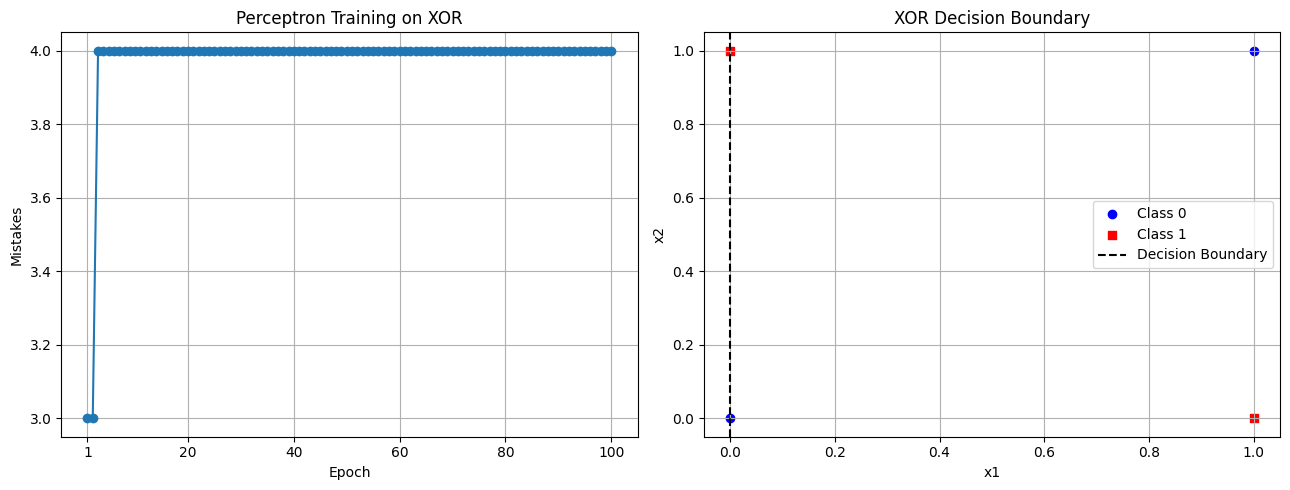

In [9]:
# Task 4.1
X_xor = np.array([
    [0, 0],
    [0, 1],
    [1, 0],
    [1, 1]
])

y_xor = np.array([0, 1, 1, 0])

w_xor, b_xor, mistakes_xor = train_perceptron(
    X_xor, y_xor, eta=0.1, max_epochs=100
)

print("Final mistakes:", mistakes_xor[-1])
print("Final weights:", w_xor)
print("Final bias:", b_xor)
print("Total epochs:", len(mistakes_xor))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

epochs = range(1, len(mistakes_xor) + 1)

axes[0].plot(epochs, mistakes_xor, marker='o')
axes[0].set_title("Perceptron Training on XOR")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Mistakes")
axes[0].set_xticks([1, 20, 40, 60, 80, 100])
axes[0].grid(True)

class_0 = X_xor[y_xor == 0]
class_1 = X_xor[y_xor == 1]

axes[1].scatter(class_0[:, 0], class_0[:, 1],
                color='blue', marker='o', label='Class 0')

axes[1].scatter(class_1[:, 0], class_1[:, 1],
                color='red', marker='s', label='Class 1')

plot_boundary(axes[1], w_xor, b_xor)

axes[1].set_title("XOR Decision Boundary")
axes[1].set_xlabel("x1")
axes[1].set_ylabel("x2")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

**Interpretation:** The perceptron never reaches zero mistakes: it makes 3–4 mistakes in every one of the 100 epochs and ends with 4 mistakes, w = [-0.1, 0], b = 0. XOR is not linearly separable, so no single line classifies all four points; each update fixes one point but breaks another, so the boundary keeps shifting without settling.

### Task 4.2 — Confirm no weight vector works
`check_xor(w, b)` returns True only if all four XOR constraints hold. Test 10,000 random (w₁, w₂, b) in [−5, 5].

In [10]:
# Task 4.2
def check_xor(w, b):
    return (
        np.dot(w, [0, 0]) + b < 0 and
        np.dot(w, [0, 1]) + b >= 0 and
        np.dot(w, [1, 0]) + b >= 0 and
        np.dot(w, [1, 1]) + b < 0
    )


random_weights = np.random.uniform(-5, 5, (10000, 2))
random_biases = np.random.uniform(-5, 5, 10000)

count = 0
first_solution = None

for w, b in zip(random_weights, random_biases):
    if check_xor(w, b):
        count += 1

        if first_solution is None:
            first_solution = (w, b)

print("Total combinations tested: 10000")
print("Valid solutions found:", count)

if first_solution is None:
    print("No solution found")
else:
    print("First passing weights:", first_solution[0])
    print("First passing bias:", first_solution[1])

Total combinations tested: 10000
Valid solutions found: 0
No solution found


## Part 5 — scikit-learn Perceptron on Iris

### Task 5.1 — Train and evaluate
Petal features (2, 3), Setosa vs rest; 70/30 stratified split; `Perceptron(random_state=42)`. Print accuracy, confusion matrix, report, `coef_`, `intercept_`.

In [11]:
# Task 5.1
X = iris.data[:, (2, 3)]

y = (iris.target == 0).astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

clf = Perceptron(random_state=42)
clf.fit(X_train, y_train)

y_pred = clf.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("Coefficients (coef_):", clf.coef_)
print("Intercept (intercept_):", clf.intercept_)

Accuracy: 1.0

Confusion Matrix:
[[30  0]
 [ 0 15]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        30
           1       1.00      1.00      1.00        15

    accuracy                           1.00        45
   macro avg       1.00      1.00      1.00        45
weighted avg       1.00      1.00      1.00        45

Coefficients (coef_): [[-1.3 -2.2]]
Intercept (intercept_): [4.]


**Interpretation:** The Perceptron achieved 100% accuracy, meaning it correctly classified all 45 test samples. The confusion matrix shows that all 30 non-Setosa samples and all 15 Setosa samples were correctly classified, with no false predictions.
The precision, recall, and F1-score are all 1.00 for both classes, showing excellent performance. The model successfully learned to distinguish Setosa flowers from the other two Iris species using petal length and petal width. coef_ is the weight vector w and intercept_ is the bias b from Part 1.

### Task 5.2 — Visualise the learned boundary
Boundary from `coef_[0]`, `intercept_[0]`; test set coloured by class; misclassified points as red ×.

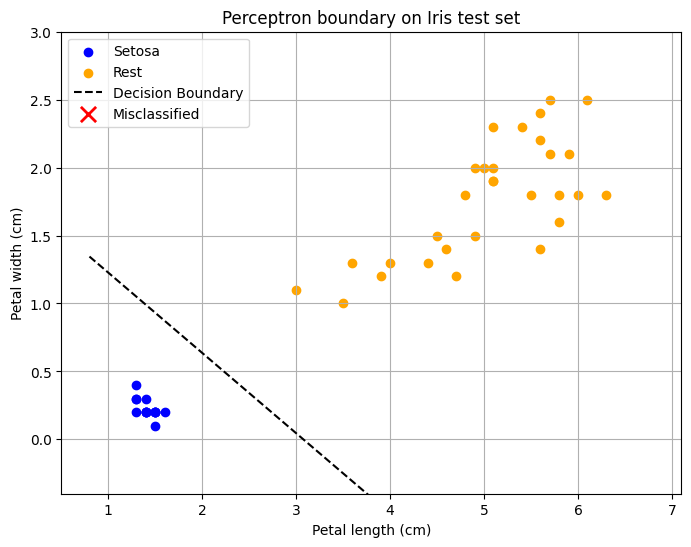

Misclassified test points: 0


In [12]:
# Task 5.2
fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(X_test[y_test == 1, 0], X_test[y_test == 1, 1], color='blue', marker='o', label='Setosa')
ax.scatter(X_test[y_test == 0, 0], X_test[y_test == 0, 1], color='orange', marker='o', label='Rest')

plot_boundary(ax, clf.coef_[0], clf.intercept_[0],
              x_range=(X_test[:, 0].min() - 0.5, X_test[:, 0].max() + 0.5))

mis = y_test != y_pred
ax.scatter(X_test[mis, 0], X_test[mis, 1], color='red', marker='x', s=120,
           linewidths=2, label='Misclassified')   # plotted last

ax.set_ylim(X_test[:, 1].min() - 0.5, X_test[:, 1].max() + 0.5)
ax.set_title("Perceptron boundary on Iris test set")
ax.set_xlabel("Petal length (cm)"); ax.set_ylabel("Petal width (cm)")
ax.legend(); ax.grid(True)
plt.show()
print("Misclassified test points:", mis.sum())

**Interpretation:** 0 of 45 test points are misclassified, so no red × appears. The boundary is a straight line separating Setosa (blue) from the rest (orange).

### Task 5.3 — Effect of learning rate
`eta0` = 0.001, 0.1, 10.0. Table of eta0 | accuracy | `n_iter_` | `coef_`. Do the predictions change? What does η do when training starts from w = 0?

In [13]:
# Task 5.3
learning_rates = [0.001, 0.1, 10.0]

results = []
predictions = {}

for eta in learning_rates:
    model = Perceptron(random_state=42, eta0=eta)
    model.fit(X_train, y_train)

    y_pred_eta = model.predict(X_test)
    predictions[eta] = y_pred_eta

    results.append({
        "eta0": eta,
        "accuracy": accuracy_score(y_test, y_pred_eta),
        "n_iter_": model.n_iter_,
        "coef_": model.coef_[0].round(4)
    })

import pandas as pd

results_df = pd.DataFrame(results)
display(results_df)

print("Predictions (0.001 vs 0.1):",
      np.array_equal(predictions[0.001], predictions[0.1]))

print("Predictions (0.1 vs 10.0):",
      np.array_equal(predictions[0.1], predictions[10.0]))

,eta0,accuracy,n_iter_,coef_
0,0.001,1.0,6,"[-0.0013, -0.0022]"
1,0.100,1.0,7,"[-0.13, -0.22]"
2,10.000,1.0,7,"[-13.0, -22.0]"


Predictions (0.001 vs 0.1): True
Predictions (0.1 vs 10.0): True


**Interpretation:** All three models achieved 100% accuracy, and their predictions remained the same despite using different learning rates. However, the learned weights became larger as the learning rate increased.

**Do the predictions change?** No. All three models have accuracy 1.0 and identical predictions.

**What does η do?** The coefficients are exactly proportional to η: [-0.0013, -0.0022], [-0.13, -0.22] and [-13.0, -22.0]. Because training starts from w = 0 and every update is η·e·x, η only rescales the whole weight vector (and bias) by a constant. The sign of z, and therefore the boundary and predictions, do not change.

## Part 6 — Multi-Class Classification

### Task 6.1 — All three Iris classes
All four features, `y = iris.target`, 70/30 stratified; `Perceptron(random_state=42, max_iter=1000)`. Print report, confusion matrix, `coef_.shape`. Which class is hardest?

In [14]:
# Task 6.1
X_multi = iris.data
y_multi = iris.target

X_train_multi, X_test_multi, y_train_multi, y_test_multi = train_test_split(
    X_multi, y_multi,
    test_size=0.3,
    random_state=42,
    stratify=y_multi
)

multi_clf = Perceptron(random_state=42, max_iter=1000)
multi_clf.fit(X_train_multi, y_train_multi)

y_pred_multi = multi_clf.predict(X_test_multi)

print("Classification Report:")
print(classification_report(y_test_multi, y_pred_multi, target_names=iris.target_names, zero_division=0
))

print("Confusion Matrix:")
print(confusion_matrix(y_test_multi, y_pred_multi))

print("coef_ shape:", multi_clf.coef_.shape)

Classification Report:
              precision    recall  f1-score   support

      setosa       0.52      1.00      0.68        15
  versicolor       0.00      0.00      0.00        15
   virginica       0.94      1.00      0.97        15

    accuracy                           0.67        45
   macro avg       0.48      0.67      0.55        45
weighted avg       0.48      0.67      0.55        45

Confusion Matrix:
[[15  0  0]
 [14  0  1]
 [ 0  0 15]]
coef_ shape: (3, 4)


**Interpretation:** The model achieved 66.67% accuracy. It correctly classified all 15 Setosa and all 15 Virginica samples, but failed to correctly classify any Versicolor samples.

The confusion matrix shows:
Setosa: All 15 samples correctly classified.
Versicolor: 14 were incorrectly classified as Setosa and 1 as Virginica.
Virginica: All 15 samples correctly classified.

**Which class is hardest?**

Each row of coef_ (shape 3×4) is the weight vector of one one-vs-rest perceptron: row 0 = setosa vs rest, row 1 = versicolor vs rest, row 2 = virginica vs rest, with one weight per feature.

Versicolor is hardest: 14 of its 15 samples were predicted as setosa. It lies between the other two classes, so one straight line cannot separate it from "rest".

### Task 6.2 — Perceptron vs Logistic Regression
`LogisticRegression(random_state=42, max_iter=200)` on the same split; side-by-side accuracy and macro-F1; why can it win (slide 32)?

In [15]:
# Task 6.2
log_reg = LogisticRegression(random_state=42, max_iter=200)
log_reg.fit(X_train_multi, y_train_multi)

y_pred_perceptron = multi_clf.predict(X_test_multi)
y_pred_logistic = log_reg.predict(X_test_multi)

perceptron_accuracy = accuracy_score(y_test_multi, y_pred_perceptron)
perceptron_f1 = f1_score(
    y_test_multi, y_pred_perceptron, average='macro'
)

logistic_accuracy = accuracy_score(y_test_multi, y_pred_logistic)
logistic_f1 = f1_score(
    y_test_multi, y_pred_logistic, average='macro'
)

comparison = pd.DataFrame({
    "Model": ["Perceptron", "Logistic Regression"],
    "Accuracy": [perceptron_accuracy, logistic_accuracy],
    "Macro-F1": [perceptron_f1, logistic_f1]
})

display(comparison)

,Model,Accuracy,Macro-F1
0,Perceptron,0.666667,0.549853
1,Logistic Regression,0.933333,0.933259


**Interpretation:** Logistic Regression scores accuracy 0.9333 and macro-F1 0.9333, against 0.6667 and 0.5499 for the Perceptron.

**Why can LR win (slide 32)?** The perceptron's step function only says "right" or "wrong", so it learns only from mistakes and has no smooth signal to improve on. Logistic regression's sigmoid gives a smooth loss whose gradient is never exactly zero, so every sample keeps adjusting the weights and it finds a better boundary when classes overlap, as versicolor and virginica do.

## Part 7 — Graded Questions (5 marks)
Answer in the Markdown cells below, using your own numbers.

**Q1 [0.5 marks] — Manual update trace.** w = [0.5, −0.3], b = 0.2, η = 0.1, x = [1, 2], y = 0. Compute z and ŷ, then e, then the updated w₁, w₂ and b.

1. Calculate weighted sum (z):

z=(0.5)(1)+(-0.3)(2)+0.2

z=0.5-0.6+0.2=0.1

2. Calculate prediction (predicted output):

Since z = 0.1 is greater than or equal to 0, the predicted output is  1.

3. Calculate error (e):

Error = Actual output − Predicted output = 0 − 1 = -1

4. Update weights and bias:

w_1=0.5+(0.1)(-1)(1)=0.4

w_2=-0.3+(0.1)(-1)(2)=-0.5

b=0.2+(0.1)(-1)=0.1

Final Answer:

(z=0.1)

(predicted output=1)

(e=-1)

Updated (w_1=0.4)

Updated (w_2=-0.5)

Updated (b=0.1)

**Q2 [0.5 marks] — Boundary geometry.** After training on AND: w = [0.3, 0.2], b = −0.4. Write the boundary equation. Which side is (1, 1) on, and what is ŷ?

1. Boundary equation:

The decision boundary is:

(w_1x_1+w_2x_2+b=0)

Substituting the values:

(0.3x_1+0.2x_2-0.4=0)

2. Check the point (1, 1):

(z=(0.3)(1)+(0.2)(1)-0.4)

(z=0.3+0.2-0.4=0.1)

Since z = 0.1 is greater than or equal to 0, the point (1, 1) lies on the positive side of the boundary.

3. Prediction:

The predicted output = 1.

**Q3 [1 mark] — XOR analysis.** (a) Show algebraically that the four XOR constraints cannot all hold. (b) Sketch XOR on x₁–x₂ axes (insert an image or a matplotlib plot) to show why no line separates it. (c) Name one architectural change that solves XOR.

(a) Algebraic proof

For XOR, the four constraints are:

For (0,0): (b<0)

For (0,1): (w2 + b is greater than or equal to zero.)

For (1,0): (w1 + b is greater than or equal to zero.)

For (1,1): (w_1+w_2+b<0)

From constraints 2 and 3:

w1 is greater than or equal to negative b, and w2 is greater than or equal to negative b.
    
Adding these inequalities:

w1 + w2 is greater than or equal to negative 2b.

Adding b to both sides:

w1 + w2 + b is greater than or equal to negative b.

Since (b<0), we know that (-b>0). Therefore:

(w_1+w_2+b>0)

But constraint 4 requires (w_1+w_2+b<0).

This is a contradiction. Therefore, all four XOR constraints cannot hold together, and a single perceptron cannot solve XOR.

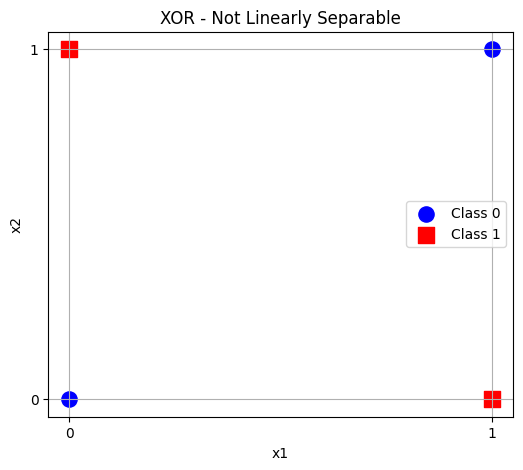

In [16]:
#(b) XOR plot
X_xor = np.array([
    [0, 0],
    [0, 1],
    [1, 0],
    [1, 1]
])

y_xor = np.array([0, 1, 1, 0])

plt.figure(figsize=(6, 5))

plt.scatter(
    X_xor[y_xor == 0, 0],
    X_xor[y_xor == 0, 1],
    color='blue',
    marker='o',
    s=120,
    label='Class 0'
)

plt.scatter(
    X_xor[y_xor == 1, 0],
    X_xor[y_xor == 1, 1],
    color='red',
    marker='s',
    s=120,
    label='Class 1'
)

plt.xlabel("x1")
plt.ylabel("x2")
plt.title("XOR - Not Linearly Separable")
plt.xticks([0, 1])
plt.yticks([0, 1])
plt.grid(True)
plt.legend()
plt.show()

# Interpretation:

The two classes are placed diagonally opposite each other. No single straight line can separate both classes correctly, which shows that XOR is not linearly separable.

# (c) Architectural change

One architectural change that solves XOR is to use a **Multi-Layer Perceptron (MLP)** with at least one hidden layer and a nonlinear activation function. The hidden layer allows the network to learn a nonlinear decision boundary and correctly classify XOR.

**Q4 [1.5 marks] — Iris extension.** Add sepal length (feature 0) so you use features (0, 2, 3). Retrain the Part 5 model; report accuracy and macro-F1. Does the extra feature help? Support your answer with numbers.

In [17]:
# Q4
X_extended = iris.data[:, [0, 2, 3]]

y_extended = (iris.target == 0).astype(int)

X_train_ext, X_test_ext, y_train_ext, y_test_ext = train_test_split(
    X_extended,
    y_extended,
    test_size=0.3,
    random_state=42,
    stratify=y_extended
)

extended_clf = Perceptron(random_state=42)
extended_clf.fit(X_train_ext, y_train_ext)

y_pred_ext = extended_clf.predict(X_test_ext)

accuracy_ext = accuracy_score(y_test_ext, y_pred_ext)
macro_f1_ext = f1_score(y_test_ext, y_pred_ext, average='macro')

print("Extended Model Accuracy:", accuracy_ext)
print("Extended Model Macro-F1:", macro_f1_ext)

accuracy_original = accuracy_score(y_test, y_pred)
macro_f1_original = f1_score(y_test, y_pred, average='macro')

print("\nOriginal Model Accuracy:", accuracy_original)
print("Original Model Macro-F1:", macro_f1_original)

Extended Model Accuracy: 1.0
Extended Model Macro-F1: 1.0

Original Model Accuracy: 1.0
Original Model Macro-F1: 1.0


The original Perceptron model used petal length and petal width (features 2 and 3), while the extended model also included sepal length (feature 0).

The original model achieved an accuracy of **1.00** and macro-F1 of **1.00**. The extended model also achieved an accuracy of **1.00** and macro-F1 of **1.00**.

Therefore, adding sepal length did not improve the model's performance. Both models achieved 100% accuracy and perfect macro-F1 scores. This shows that the original two petal features were already sufficient to correctly classify Setosa flowers from the other two Iris species.

**Q5 [1.5 marks] — Synthetic data.** `make_classification(n_samples=200, n_features=2, n_redundant=0, n_clusters_per_class=1, random_state=42)`, 70/30 split. Train your hand-built perceptron and sklearn's. Compare accuracy, epochs, final w and b; plot both boundaries side by side.

HAND-BUILT PERCEPTRON
Accuracy: 0.6333333333333333
Epochs: 1000
Final weights: [ 0.13546212 -0.06914304]
Final bias: 0.20000000000000004

SCIKIT-LEARN PERCEPTRON
Accuracy: 0.6666666666666666
Epochs: 6
Final weights: [2.28133191 0.57972588]
Final bias: 2.0


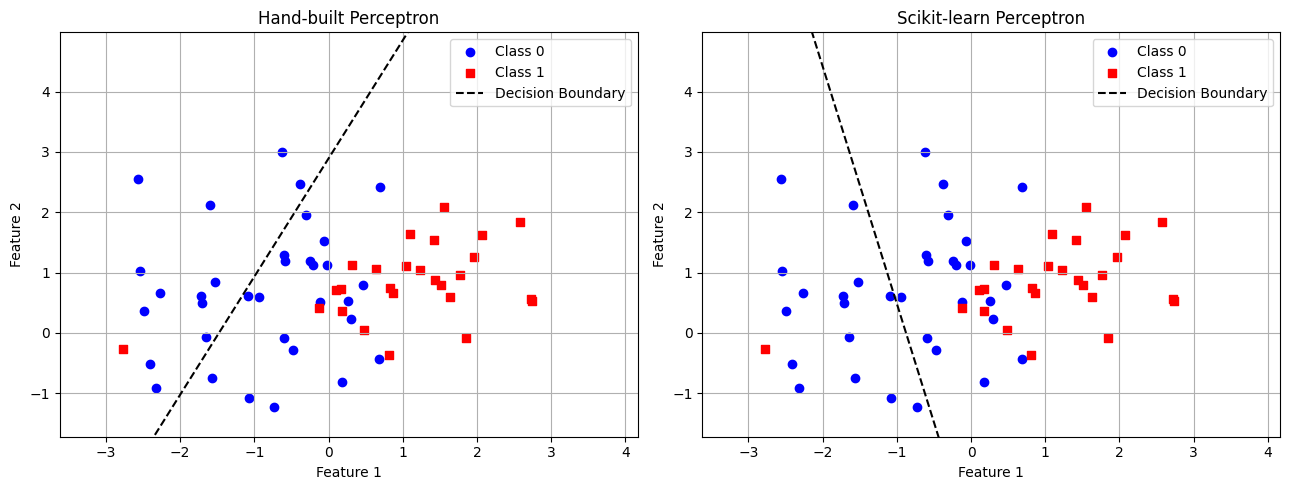

In [18]:
# Q5
X_syn, y_syn = make_classification(
    n_samples=200,
    n_features=2,
    n_redundant=0,
    n_clusters_per_class=1,
    random_state=42
)

X_train_syn, X_test_syn, y_train_syn, y_test_syn = train_test_split(
    X_syn, y_syn,
    test_size=0.3,
    random_state=42
)

w_hand, b_hand, mistakes_hand = train_perceptron(
    X_train_syn, y_train_syn,
    eta=0.1,
    max_epochs=1000
)

sklearn_clf = Perceptron(random_state=42, max_iter=1000)
sklearn_clf.fit(X_train_syn, y_train_syn)

y_pred_hand = np.array([
    predict(w_hand, x, b_hand) for x in X_test_syn
])

y_pred_sklearn = sklearn_clf.predict(X_test_syn)

accuracy_hand = accuracy_score(y_test_syn, y_pred_hand)
accuracy_sklearn = accuracy_score(y_test_syn, y_pred_sklearn)

print("HAND-BUILT PERCEPTRON")
print("Accuracy:", accuracy_hand)
print("Epochs:", len(mistakes_hand))
print("Final weights:", w_hand)
print("Final bias:", b_hand)

print("\nSCIKIT-LEARN PERCEPTRON")
print("Accuracy:", accuracy_sklearn)
print("Epochs:", sklearn_clf.n_iter_)
print("Final weights:", sklearn_clf.coef_[0])
print("Final bias:", sklearn_clf.intercept_[0])

def plot_synthetic_boundary(ax, w, b, title):
    x_min = X_syn[:, 0].min() - 0.5
    x_max = X_syn[:, 0].max() + 0.5

    if w[1] != 0:
        x1 = np.linspace(x_min, x_max, 100)
        x2 = -(w[0] * x1 + b) / w[1]
        ax.plot(x1, x2, 'k--', label='Decision Boundary')
    elif w[0] != 0:
        x_vertical = -b / w[0]
        ax.axvline(x_vertical, color='black',
                   linestyle='--', label='Decision Boundary')

    ax.set_xlim(x_min, x_max)
    ax.set_ylim(X_syn[:, 1].min() - 0.5,
                X_syn[:, 1].max() + 0.5)

    ax.set_title(title)
    ax.set_xlabel("Feature 1")
    ax.set_ylabel("Feature 2")
    ax.legend()
    ax.grid(True)


fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax in axes:
    ax.scatter(
        X_test_syn[y_test_syn == 0, 0],
        X_test_syn[y_test_syn == 0, 1],
        color='blue',
        marker='o',
        label='Class 0'
    )

    ax.scatter(
        X_test_syn[y_test_syn == 1, 0],
        X_test_syn[y_test_syn == 1, 1],
        color='red',
        marker='s',
        label='Class 1'
    )

plot_synthetic_boundary(
    axes[0], w_hand, b_hand, "Hand-built Perceptron"
)

plot_synthetic_boundary(
    axes[1], sklearn_clf.coef_[0],
    sklearn_clf.intercept_[0],
    "Scikit-learn Perceptron"
)
plt.tight_layout()
plt.show()

**Interpretation:** Hand-built: accuracy 0.6333, 1000 epochs, w = [0.1355, -0.0691], b = 0.2. scikit-learn: accuracy 0.6667, 6 epochs, w = [2.2813, 0.5797], b = 2.0.

The data is not perfectly linearly separable, so my perceptron never reaches zero mistakes and runs all 1000 epochs. scikit-learn stopped after 6 epochs because of its tolerance rule, not because it converged. The accuracy gap is only 2 of 60 test samples, so neither model is clearly better. The boundaries differ because the perceptron has no convergence guarantee on non-separable data, so the final weights depend on data order (sklearn shuffles) and when training stops.